# 05 — Is the mirage the model following "you must answer"? The pressure vector

**Question.** The generation prompt says the model MUST give a definitive answer, never "unknown", and should guess if uncertain. Is that instruction represented as a direction, and is it the same direction that separates mirage from abstain?

**Methods.** For every SLAKE question, without the image, the pre-answer state under two system prompts that differ only in those two pressure sentences (`miragelab/pressure.py`, checked to reproduce the extracted states at cos > 0.99). Unit = distinct question text (284; the whole no-image input). Pressure vector p = unit mean of (pressure − neutral), paired per text, on the 70% fit texts (same split as steering). Compared with the behaviour directions (mirage−abstain, hedged−abstain, mirage−hedged) from notebook 04, raw and type-centred. Null: cosine between random directions in 2560-d ≈ ±0.02.

In [1]:
import sys, subprocess, numpy as np, pandas as pd, matplotlib.pyplot as plt
import os; BENCH = os.environ.get('MIRAGE_ROOT', '..'); sys.path.insert(0, '..')  # BENCH: data root with runs/
from miragelab import analysis as A
df, acts, meta = A.load(BENCH + '/runs/slake'); L = meta['layers']
neu = np.load(BENCH + '/runs/slake/acts_neutral.npy', mmap_mode='r')
OUTC = ['abstain', 'hedged', 'mirage']; col = {'abstain': 'tab:blue', 'hedged': 'tab:orange', 'mirage': 'tab:red'}
# unit = distinct question text (the whole no-image input); same 70/30 text split as steering
idx, lab, nrec, stable = A.unique_texts(df)
texts = df.question.map(A.norm_text).values[idx]; cat = df.category.values[idx]
tr = A.text_split(texts, 0.7, seed=0, strat=lab); te = ~tr
PS = np.asarray(acts[idx, 1, 0], 'f4'); NS = np.asarray(neu[idx], 'f4')      # [text, layer, d]
print('distinct texts', len(idx), '| fit', tr.sum(), 'held-out', te.sum(), '| pressure', PS.shape, 'neutral', NS.shape)

distinct texts 284 | fit 199 held-out 85 | pressure (284, 18, 2560) neutral (284, 18, 2560)


## 1. Is there a stable pressure direction, and does it line up with the behaviour directions?
**Methods.** Per layer: size of the pressure shift relative to the state norm (the edit changes the same system-prompt tokens for every question, so p is near-constant across questions — a split-half check would be trivially 1); cosine of p with each behaviour direction (train); random-direction null.

,rel_shift,cos p·(mirage−abstain) raw,cos p·(hedged−abstain) raw,cos p·(mirage−hedged) raw,cos p·(mirage−abstain) centred,cos p·(hedged−abstain) centred,cos p·(mirage−hedged) centred
layer,,,,,,,
2,0.038,0.150,0.030,0.203,0.052,0.231,-0.157
4,0.039,0.056,-0.028,0.125,-0.022,-0.038,0.015
6,0.028,-0.042,-0.116,0.050,-0.048,-0.066,0.015
8,0.031,-0.076,-0.109,-0.014,-0.197,-0.172,-0.007
10,0.045,-0.001,0.024,-0.030,-0.002,0.028,-0.025
12,0.047,-0.052,0.030,-0.128,-0.029,0.148,-0.150
14,0.060,-0.043,0.065,-0.150,-0.110,0.146,-0.201
16,0.079,-0.076,-0.026,-0.109,-0.120,-0.010,-0.101
18,0.097,-0.041,0.032,-0.102,-0.139,0.029,-0.132


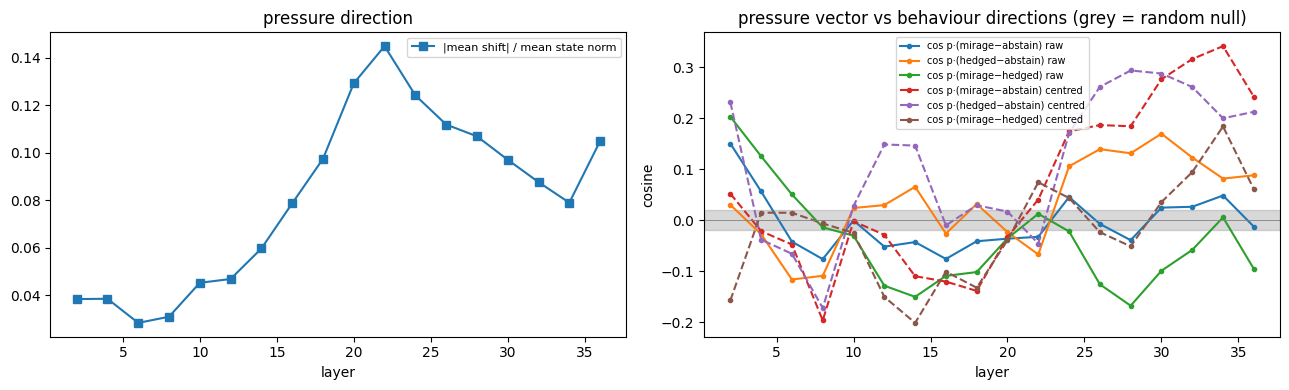

In [2]:
rows = []
for j, l in enumerate(L):
    P, Q = PS[:, j], NS[:, j]
    p = A.paired_direction(P[tr], Q[tr])
    shift = float(np.linalg.norm((P[tr] - Q[tr]).mean(0)) / np.linalg.norm(P[tr], axis=1).mean())
    r = dict(layer=l, rel_shift=shift)
    for space, X in [('raw', P), ('centred', A.center_by(P, cat, tr))]:
        for a, b in [('mirage', 'abstain'), ('hedged', 'abstain'), ('mirage', 'hedged')]:
            m = tr & np.isin(lab, [a, b])
            r[f'cos p·({a}−{b}) {space}'] = float(p @ A.diff_of_means(X[m], lab[m] == a))
    rows.append(r)
C = pd.DataFrame(rows).set_index('layer'); display(C.round(3))
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(C.index, C.rel_shift, marker='s', label='|mean shift| / mean state norm')
axs[0].set(xlabel='layer', title='pressure direction'); axs[0].legend(fontsize=8)
for c in [c for c in C.columns if c.startswith('cos')]:
    axs[1].plot(C.index, C[c], marker='o', ms=3, ls='-' if 'raw' in c else '--', label=c)
axs[1].axhspan(-.02, .02, color='grey', alpha=.3); axs[1].axhline(0, c='grey', lw=.6)
axs[1].set(xlabel='layer', ylabel='cosine', title='pressure vector vs behaviour directions (grey = random null)'); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Results.** The pressure edit shifts the pre-answer state by 3–15% of its norm (largest at L20–22). Cosine of the pressure direction with the behaviour directions: raw mirage−abstain |cos| ≤ 0.08 at every layer except L2 (0.15); raw hedged−abstain 0.08–0.17 at L24–36; type-centred 0.17–0.34 (mirage−abstain) and 0.17–0.29 (hedged−abstain) at L24–36.

**Discussion.** See 1b — these cosines must be compared with how much a direction estimated from ~130 texts moves under label noise.

### 1b. Is the alignment above chance? Label-shuffle null
**Methods.** For each layer: shuffle outcome labels among fit texts 200×, refit the (type-centred / raw) mirage−abstain and hedged−abstain directions, take |cos| with p. Report observed cos, the null 95th percentile, and the permutation p-value (`perm_cos_null`).

cos                                               \
space                raw                  type-centred                  
direction hedged−abstain mirage−abstain hedged−abstain mirage−abstain   
layer                                                                   
2                  0.030          0.150          0.231          0.052   
4                 -0.028          0.056         -0.038         -0.022   
6                 -0.116         -0.042         -0.066         -0.048   
8                 -0.109         -0.076         -0.172         -0.197   
10                 0.024         -0.001          0.028         -0.002   
12                 0.030         -0.052          0.148         -0.029   
14                 0.065         -0.043          0.146         -0.110   
16                -0.026         -0.076         -0.010         -0.120   
18                 0.032         -0.041          0.029         -0.139   
20                -0.023         -0.036          0.017         -0.033   
22                -0.067         -0.033         -0.046          0.040   
24                 0.106          0.045          0.171          0.174   
26                 0.139         -0.007          0.261          0.186   
28                 0.131         -0.039          0.294          0.184   
30                 0.170          0.025          0.288          0.276   
32                 0.123          0.026          0.261          0.316   
34                 0.082          0.048          0.200          0.341   
36                 0.088         -0.013          0.212          0.242   

                       p                                               
space                raw                  type-centred                 
direction hedged−abstain mirage−abstain hedged−abstain mirage−abstain  
layer                                                                  
2                  0.905          0.622          0.328          0.836  
4                  0.766          0.572          0.741          0.786  
6                  0.194          0.637          0.493          0.657  
8                  0.259          0.463          0.104          0.040  
10                 0.711          1.000          0.716          0.980  
12                 0.682          0.582          0.169          0.801  
14                 0.463          0.572          0.095          0.249  
16                 0.796          0.433          0.935          0.289  
18                 0.751          0.632          0.771          0.184  
20                 0.622          0.602          0.826          0.652  
22                 0.423          0.741          0.587          0.706  
24                 0.438          0.761          0.279          0.254  
26                 0.527          0.995          0.199          0.408  
28                 0.597          0.886          0.169          0.488  
30                 0.517          0.925          0.209          0.269  
32                 0.587          0.910          0.274          0.214  
34                 0.711          0.796          0.398          0.134  
36                 0.647          0.945          0.249          0.244

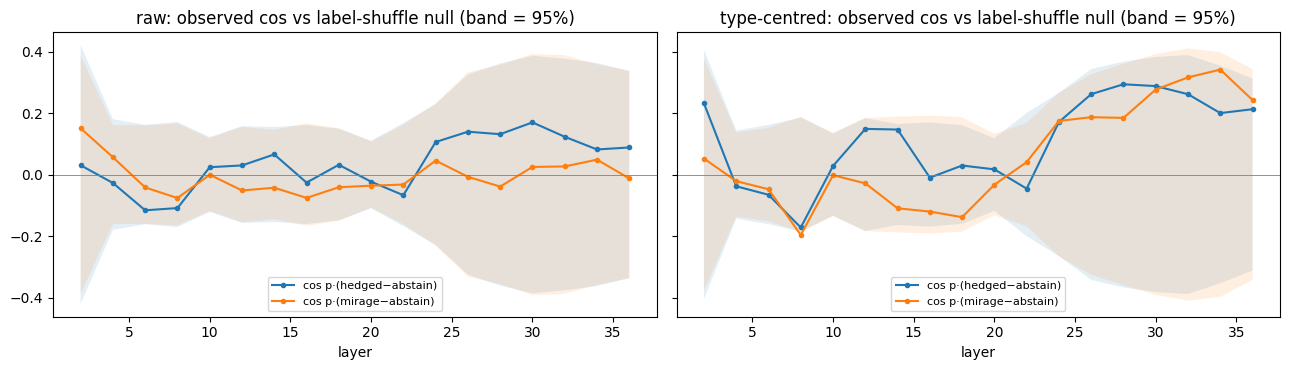

In [3]:
pn = []
for j, l in enumerate(L):
    p = A.paired_direction(PS[tr, j], NS[tr, j])
    for space, cc in [('raw', None), ('type-centred', cat)]:
        for a in ['mirage', 'hedged']:
            obs, q95, pv = A.perm_cos_null(PS[:, j], lab, tr, p, a=a, b='abstain', cat=cc, n=200)
            pn.append((l, space, f'{a}−abstain', obs, q95, pv))
PN = pd.DataFrame(pn, columns=['layer', 'space', 'direction', 'cos', 'null q95 |cos|', 'p'])
display(PN.pivot_table(index='layer', columns=['space', 'direction'], values=['cos', 'p']).round(3))
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, space in zip(axs, ['raw', 'type-centred']):
    for d_, g_ in PN[PN.space == space].groupby('direction'):
        ax.plot(g_.layer, g_['cos'], marker='o', ms=3, label=f'cos p·({d_})'); ax.fill_between(g_.layer, -g_['null q95 |cos|'], g_['null q95 |cos|'], alpha=.12)
    ax.axhline(0, c='grey', lw=.6); ax.set(title=f'{space}: observed cos vs label-shuffle null (band = 95%)', xlabel='layer'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Results.** Label-shuffle null (200 permutations): no late-layer alignment is above chance — type-centred mirage−abstain p = 0.13–0.49 at L24–36, hedged−abstain p = 0.17–0.40; raw p ≥ 0.42. One p < 0.05 (L8 type-centred mirage−abstain, 0.04) out of 72 tests, about what chance gives.

**Discussion.** No evidence that the 'you must answer' instruction direction is the mirage or hedge direction. The type-centred cosines of ~0.3 are within the noise of estimating a behaviour direction from this many texts.

## 2. Does removing the pressure move states toward abstain, and for whom?
**Methods.** Held-out texts (30%). For each, the shift (neutral − pressure) projected on the train mirage→abstain unit direction (positive = toward abstain), by outcome under pressure. Also: each outcome's mean projection on p (how much 'pressure' the state carries). Layer = best type-centred mirage-vs-abstain validation AUC (`best_layer_centred`, the same rule steering uses).

layer (best type-centred CV AUC on fit texts, same rule as steering): 34


toward_abstain        on_pressure       
                  mean    sem        mean    sem
outcome                                         
abstain         -0.205  0.716   38.207001  2.282
hedged           2.500  0.564   36.021000  1.952
mirage          -0.147  0.492   34.298000  2.226

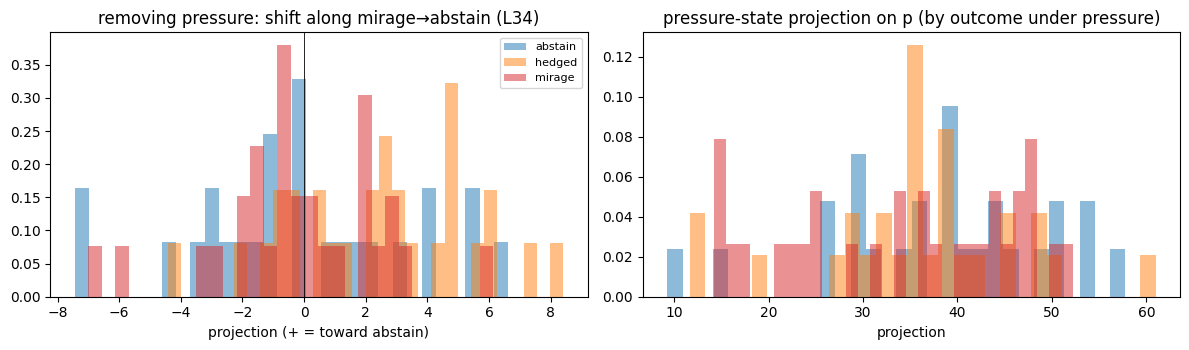

In [4]:
m = tr & np.isin(lab, ['mirage', 'abstain'])
aucs = [A.one_vector_auc_cv(PS[m, j], lab[m] == 'mirage', np.arange(m.sum()), center=cat[m]) for j in range(len(L))]
jl = int(np.argmax(aucs)); l = L[jl]; print('layer (best type-centred CV AUC on fit texts, same rule as steering):', l)
P, Q = PS[:, jl], NS[:, jl]
u = -A.diff_of_means(P[m], lab[m] == 'mirage')        # points mirage -> abstain (fit texts)
p = A.paired_direction(P[tr], Q[tr])
sh = pd.DataFrame(dict(outcome=lab[te], toward_abstain=(Q[te] - P[te]) @ u, on_pressure=(P[te] - Q[tr].mean(0)) @ p))
display(sh.groupby('outcome')[['toward_abstain', 'on_pressure']].agg(['mean', 'sem']).round(3))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for o in OUTC:
    d = sh[sh.outcome == o]
    axs[0].hist(d.toward_abstain, bins=30, alpha=.5, color=col[o], density=True, label=o)
    axs[1].hist(d.on_pressure, bins=30, alpha=.5, color=col[o], density=True, label=o)
axs[0].axvline(0, c='k', lw=.6); axs[0].set(title=f'removing pressure: shift along mirage→abstain (L{l})', xlabel='projection (+ = toward abstain)')
axs[1].set(title='pressure-state projection on p (by outcome under pressure)', xlabel='projection'); axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Results** (L34, 85 held-out texts). Removing the pressure moves hedged states toward abstain by +2.5 ± 0.6 (≈6% of the mirage–abstain gap); abstain −0.2 ± 0.7 and mirage −0.1 ± 0.5 do not move. Projection on the pressure direction is similar for all outcomes (34–38).

**Discussion.** The instruction's effect on the state is small and shows only in hedged cases. Pure mirage states don't respond to removing it.

## 3. Geometry: both prompts on one map
**Methods.** All 284 distinct texts, both prompts, same layer. PCA (linear view — the one a steering vector acts in) and PHATE. Colour = outcome under pressure; marker = prompt; thin lines join each question's two states (60 per outcome).

~/lab/benches/mats-nanda/.venv/lib/python3.10/site-packages/phate/phate.py:919: RuntimeWarning: Graph is disconnected with 6 connected components. This may indicate that your knn parameter (currently 5) is too small, or that your data contains distinct clusters. PHATE may not accurately represent relationships between disconnected components.
  warnings.warn(


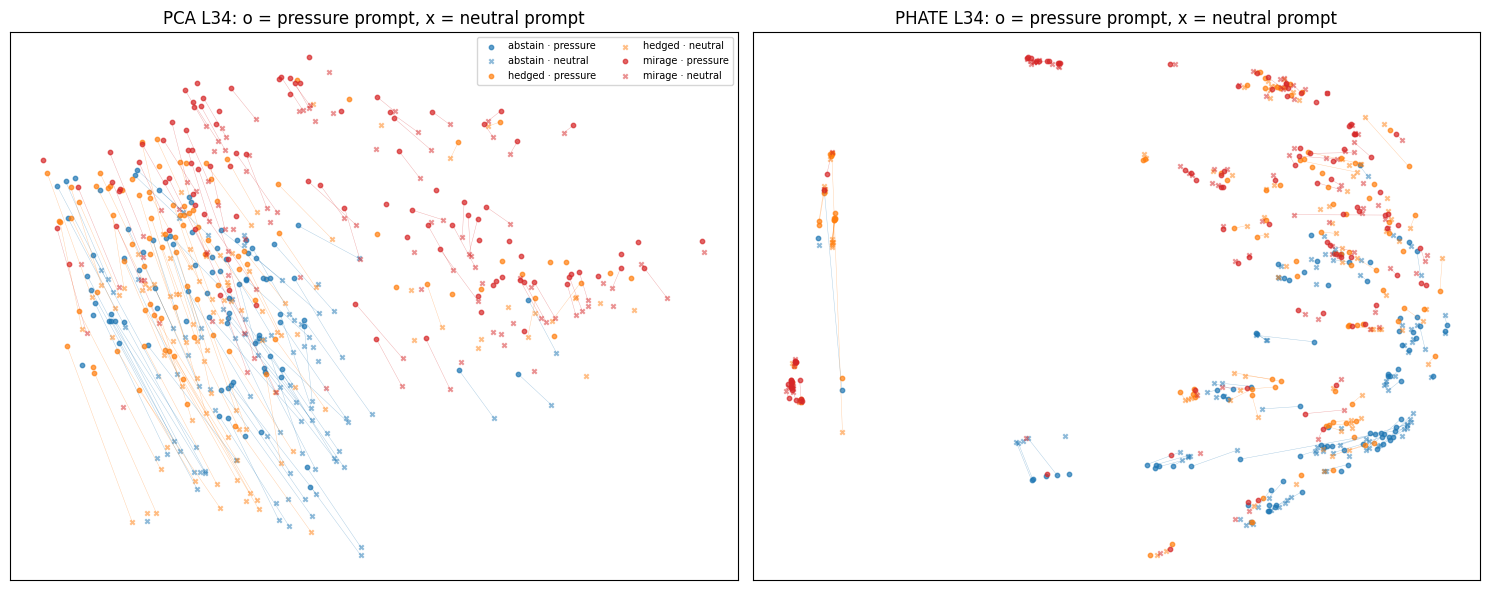

In [5]:
ii = np.arange(len(idx)); Xb = np.r_[P[ii], Q[ii]]; labs = lab[ii]; n = len(ii)
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
for ax, meth in zip(axs, ['pca', 'phate']):
    Z = A.embed(Xb, meth); Zp, Zn = Z[:n], Z[n:]
    for o in OUTC:
        s = labs == o
        ax.scatter(Zp[s, 0], Zp[s, 1], s=10, c=col[o], alpha=.7, marker='o', label=f'{o} · pressure')
        ax.scatter(Zn[s, 0], Zn[s, 1], s=10, c=col[o], alpha=.5, marker='x', label=f'{o} · neutral')
        for k in np.where(s)[0][:60]: ax.plot([Zp[k, 0], Zn[k, 0]], [Zp[k, 1], Zn[k, 1]], c=col[o], lw=.3, alpha=.4)
    ax.set_title(f'{meth.upper()} L{l}: o = pressure prompt, x = neutral prompt'); ax.set_xticks([]); ax.set_yticks([])
axs[0].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

## 4. Discussion

- **The 'must answer' instruction is represented** (a consistent shift of 3–15% of the state norm), **but it is not the mirage direction**: its alignment with mirage−abstain and hedged−abstain is not distinguishable from a label-shuffle null at any late layer.
- **Removing it** nudges only hedged states toward abstain (~6% of the gap); pure mirage states don't move.
- **Reading:** hedging looks partly like complying with the answer instruction; pure mirage doesn't look like instruction-following in this representation. Earlier per-record cosines of 0.2–0.3 were an artefact of repeated question texts.
- **Limits:** 284 distinct texts (199 fit / 85 held out) limits power — a small real alignment could be missed; state read at one token (last prompt token); only one pressure wording removed.